In [1]:
import os, sys
%pylab inline
plt.style.use('default')
import pandas as pd
from importlib import reload
spines_off = lambda ax: [ax.spines[side].set_visible(False) for side in ['top', 'right']]

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [7]:
import dnos.src.paths as paths
import dnos.src.data as dnos_data
reload(dnos_data)
df = dnos_data.get_noni_ripeness(do_zscore=True)

In [4]:
import dnos.src.sechellia as sechellia
import dnos.src.common as common

In [5]:
reload(dnos_data)
reload(sechellia)
A = sechellia.Analysis(seed = 2)
results = A.fit_models()#results=results)

In [6]:
A.compute_lasso_sparsity()
A.compute_pc_var_overlap()
A.compute_confusion_matrices()
A.compute_p_values(n_rand=1000)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:34<00:00, 28.78it/s]


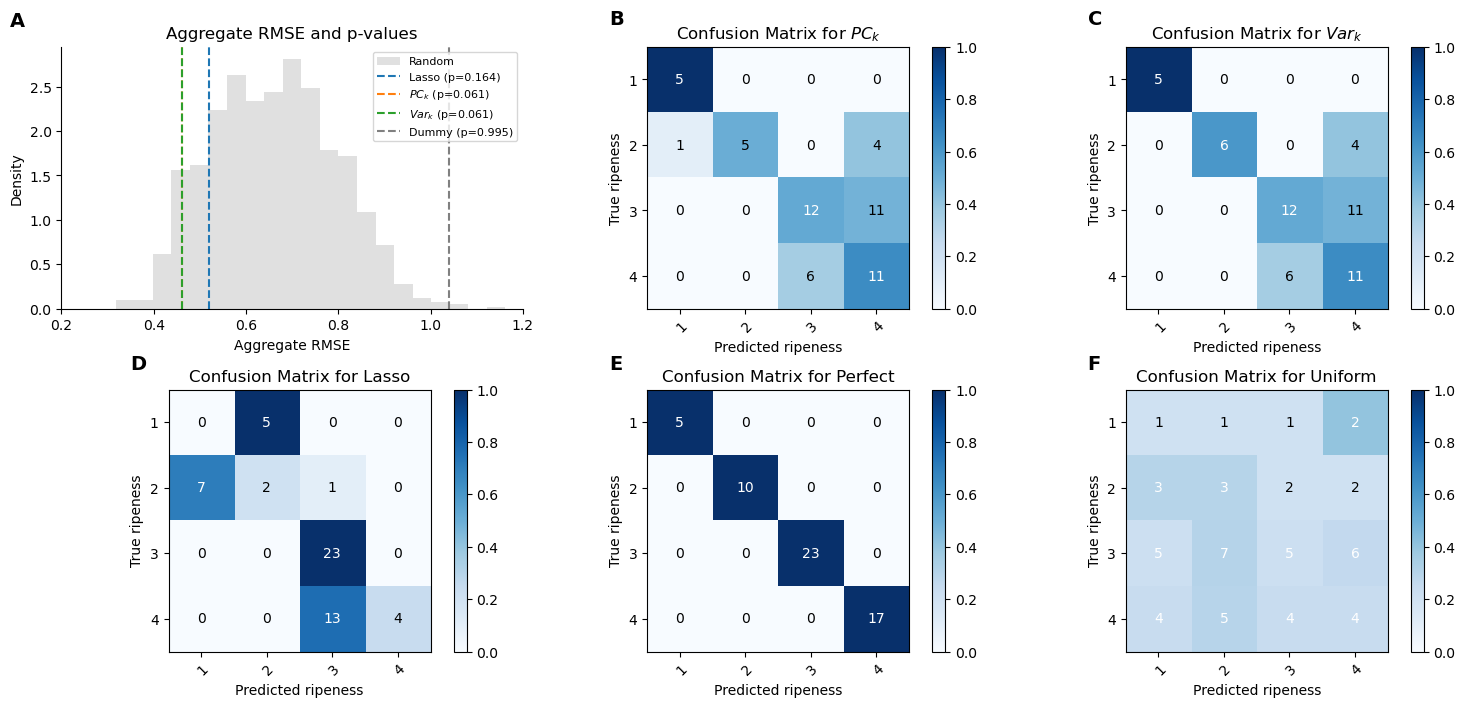

In [11]:
reload(common)
reload(sechellia)
pr = sechellia.PlotResults(A, colorby="fold")
pr.plot_figure(panels=[
    (0, 0, "A", pr.plot_aggregate_p_values, ["lasso", "pc_k", "var_k", "dummy"]),
    (0, 1, "B", pr.plot_confusion_matrix, "pc_k"),
    (0, 2, "C", pr.plot_confusion_matrix, "var_k"),
    (1, 0, "D", pr.plot_confusion_matrix, "lasso"), 
    (1, 1, "E", pr.plot_confusion_matrix, "perfect"),
    (1, 2, "F", pr.plot_confusion_matrix, "uniform")
])
plt.savefig(os.path.join(paths.figs_path, "sechellia.pdf"), bbox_inches=None)


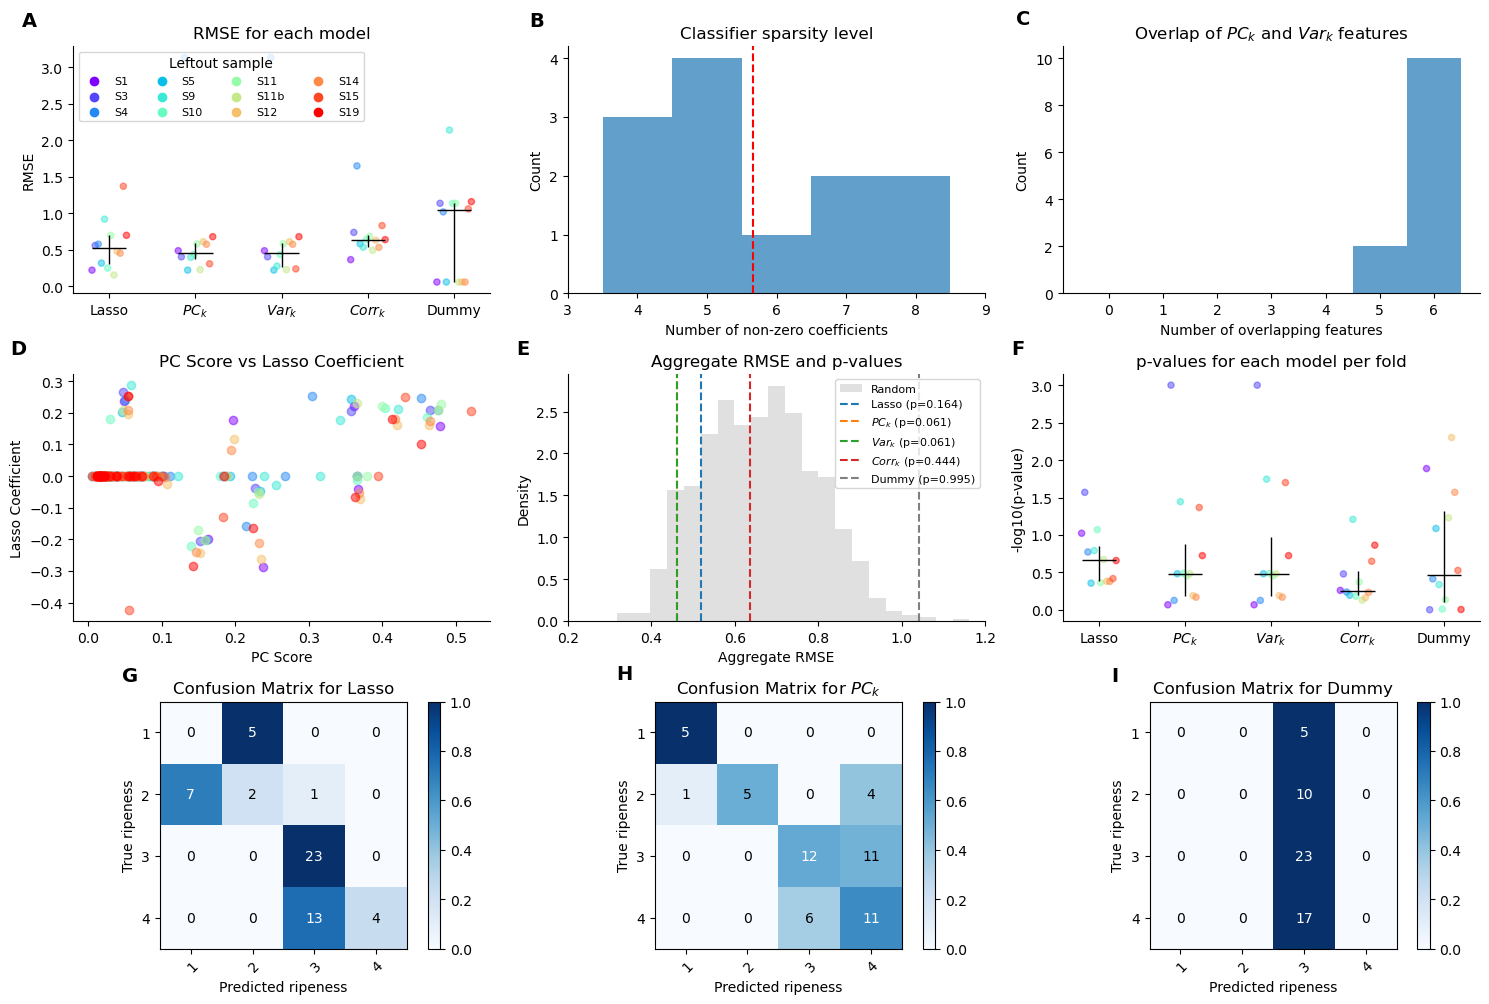

In [10]:
pr.plot_figure()
plt.savefig(os.path.join(paths.figs_path, "sechellia_all.pdf"), bbox_inches=None)